# ArchiveLens Mini: an OCR-searchable digital archive prototype

**Author:** Arora Abir, Master of Artificial Intelligence student, Memorial University of Newfoundland  
**GitHub:** [github.com/arora2934/archivelens](https://github.com/arora2934/archivelens)

**Goal:** turn scanned archive pages into searchable text, store them in a database, and search them through an API.

**Pipeline:** sample scans → image cleaning (OpenCV) → OCR (Tesseract) → accuracy check → SQLite database with full-text search → FastAPI search endpoint

**About the data:** all documents in this notebook are **fictional samples** created in Step 1. I chose fictional pages so the project is free of copyright issues, and so I know the exact correct text and can measure OCR accuracy.



## Step 0: Setup
Installs the Tesseract OCR engine and the Python libraries. In Colab, run this cell again every time you reopen the notebook.

In [1]:
import shutil
if shutil.which("tesseract") is None:
    !apt-get install -y tesseract-ocr > /dev/null
!pip install -q pytesseract fastapi httpx opencv-python-headless pandas matplotlib > /dev/null 2>&1

import os, io, json, re, sqlite3, textwrap
import numpy as np
import pandas as pd
import cv2
import pytesseract
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image, ImageDraw, ImageFont, ImageFilter

os.makedirs("data/samples", exist_ok=True)
os.makedirs("src", exist_ok=True)
os.makedirs("api", exist_ok=True)
print("Tesseract version:", pytesseract.get_tesseract_version())

Tesseract version: 5.3.4


## Step 1: Create sample archive documents
I've generated 5 fictional "old newspaper notices" as images, with three levels of damage so they look like real scans:
- **light** (docs 1 to 3): a little noise and tilt
- **moderate** (doc 4): faded ink, stains, low resolution, strong JPEG compression
- **heavy** (doc 5): all of the above, even worse, to test the limits of OCR

Because I wrote the text myself, I keep the **ground truth** (the correct text) to measure accuracy in Step 2.

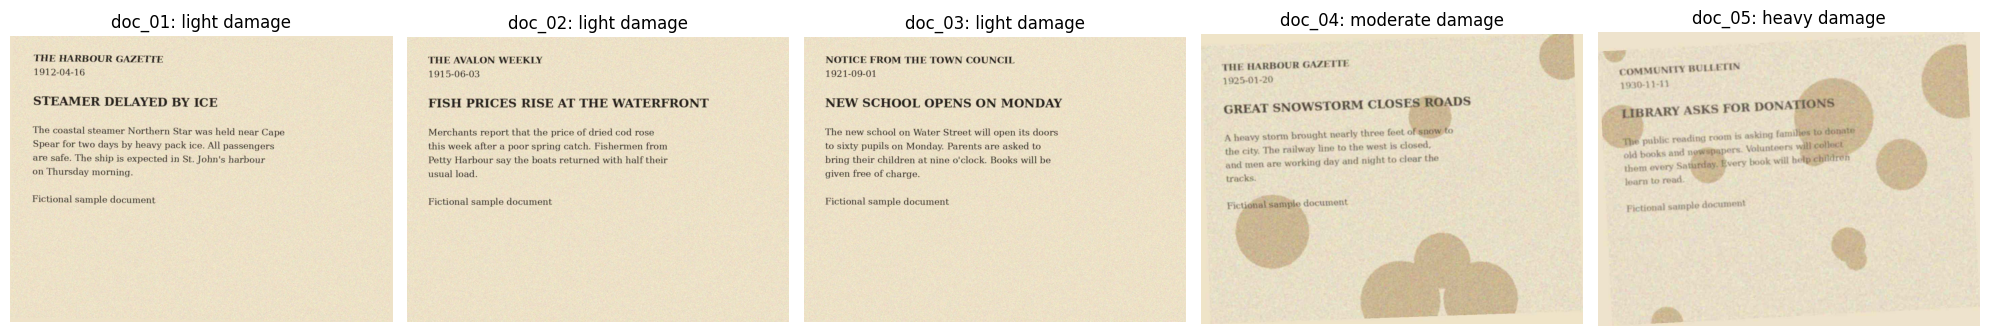

In [2]:
DOCS = [
    {"id": 1, "source": "The Harbour Gazette", "date": "1912-04-16", "category": "Shipping",
     "headline": "STEAMER DELAYED BY ICE",
     "body": "The coastal steamer Northern Star was held near Cape Spear for two days by heavy pack ice. "
             "All passengers are safe. The ship is expected in St. John's harbour on Thursday morning."},
    {"id": 2, "source": "The Avalon Weekly", "date": "1915-06-03", "category": "Fisheries",
     "headline": "FISH PRICES RISE AT THE WATERFRONT",
     "body": "Merchants report that the price of dried cod rose this week after a poor spring catch. "
             "Fishermen from Petty Harbour say the boats returned with half their usual load."},
    {"id": 3, "source": "Notice from the Town Council", "date": "1921-09-01", "category": "Education",
     "headline": "NEW SCHOOL OPENS ON MONDAY",
     "body": "The new school on Water Street will open its doors to sixty pupils on Monday. "
             "Parents are asked to bring their children at nine o'clock. Books will be given free of charge."},
    {"id": 4, "source": "The Harbour Gazette", "date": "1925-01-20", "category": "Weather",
     "headline": "GREAT SNOWSTORM CLOSES ROADS", "damage": "moderate",
     "body": "A heavy storm brought nearly three feet of snow to the city. The railway line to the west "
             "is closed, and men are working day and night to clear the tracks."},
    {"id": 5, "source": "Community Bulletin", "date": "1930-11-11", "category": "Community",
     "headline": "LIBRARY ASKS FOR DONATIONS",
     "body": "The public reading room is asking families to donate old books and newspapers. "
             "Volunteers will collect them every Saturday. Every book will help children learn to read.",
     "damage": "heavy"},
]

SERIF = font_manager.findfont(font_manager.FontProperties(family="DejaVu Serif"))
SERIF_BOLD = font_manager.findfont(font_manager.FontProperties(family="DejaVu Serif", weight="bold"))

def page_lines(doc):
    """The exact lines printed on the page (this is the ground truth)."""
    return ([doc["source"].upper(), doc["date"], "", doc["headline"], ""]
            + textwrap.wrap(doc["body"], width=52)
            + ["", "Fictional sample document"])

# How much damage each level adds
DAMAGE = {
    "light":    dict(ink=(40, 35, 30), stains=0,  noise=14, shrink=1.0,  blur=0.6, tilt=None, jpeg=90),
    "moderate": dict(ink=(80, 72, 60), stains=6,  noise=30, shrink=0.55, blur=1.0, tilt=2.0,  jpeg=40),
    "heavy":    dict(ink=(95, 85, 72), stains=10, noise=34, shrink=0.5,  blur=1.2, tilt=3.0,  jpeg=32),
}

def make_scan(doc, seed):
    rng = np.random.default_rng(seed)
    p = DAMAGE[doc.get("damage", "light")]
    img = Image.new("RGB", (1100, 820), (238, 226, 200))            # old paper colour
    draw = ImageDraw.Draw(img)
    for _ in range(p["stains"]):                                      # brown stains
        cx, cy, r = rng.integers(0, 1100), rng.integers(0, 820), rng.integers(30, 120)
        draw.ellipse((cx - r, cy - r, cx + r, cy + r), fill=(205, 184, 148))
    y = 50
    for i, line in enumerate(page_lines(doc)):
        size = 34 if i == 3 else 26
        font = ImageFont.truetype(SERIF_BOLD if i in (0, 3) else SERIF, size)
        draw.text((60, y), line, fill=p["ink"], font=font)
        y += size + 14
    arr = np.asarray(img).astype(float) + rng.normal(0, p["noise"], (820, 1100, 3))   # scanner noise
    img = Image.fromarray(np.clip(arr, 0, 255).astype("uint8"))
    if p["shrink"] < 1:                                               # low-resolution scan
        w, h = img.size
        img = img.resize((int(w * p["shrink"]), int(h * p["shrink"])), Image.BILINEAR).resize((w, h), Image.BILINEAR)
    img = img.filter(ImageFilter.GaussianBlur(p["blur"]))
    tilt = p["tilt"] if p["tilt"] is not None else rng.uniform(-1.5, 1.5)   # page placed a bit crooked
    img = img.rotate(tilt, expand=True, fillcolor=(238, 226, 200))
    buf = io.BytesIO()
    img.save(buf, "JPEG", quality=p["jpeg"])                          # compression artefacts
    return Image.open(buf).convert("RGB")

ground_truth = {}
for doc in DOCS:
    path = f"data/samples/doc_{doc['id']:02d}.png"
    make_scan(doc, seed=doc["id"]).save(path)
    doc["image_path"] = path
    ground_truth[doc["id"]] = "\n".join(page_lines(doc))

with open("data/ground_truth.json", "w") as f:
    json.dump(ground_truth, f, indent=2)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, doc in zip(axes, DOCS):
    ax.imshow(Image.open(doc["image_path"])); ax.set_title(f"doc_{doc['id']:02d}: {doc.get('damage', 'light')} damage"); ax.axis("off")
plt.tight_layout(); plt.show()

## Step 2: OCR and accuracy check
1. **Clean** each image with OpenCV: grayscale, remove small noise, then an **adaptive threshold** that turns the page into black text on white, even where stains make the paper darker.
2. **OCR** both the raw and the cleaned image with Tesseract. The pipeline keeps the cleaned text.
3. **Measure accuracy** with the Character Error Rate (CER): the share of characters OCR got wrong compared with the ground truth. Lower is better. Accuracy = 1 - CER.

In [3]:
def clean_image(path):
    gray = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2GRAY)        # remove colour
    gray = cv2.medianBlur(gray, 3)                                    # remove small noise dots
    return cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,  # black text on white,
                                 cv2.THRESH_BINARY, 31, 15)            # judged area by area

def ocr(image):
    text = pytesseract.image_to_string(image)
    data = pytesseract.image_to_data(image, output_type=pytesseract.Output.DICT)
    confs = [float(c) for c in data["conf"] if float(c) >= 0]         # -1 means "not a word"
    return text, (sum(confs) / len(confs) if confs else 0.0)

def normalize(text):
    return re.sub(r"\s+", " ", text).strip().lower()

def cer(truth, guess):
    """Character Error Rate = edit distance / length of the correct text."""
    a, b = normalize(truth), normalize(guess)
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1] / max(len(a), 1)

rows = []
for doc in DOCS:
    raw_text, _ = ocr(Image.open(doc["image_path"]))
    clean_text, conf = ocr(clean_image(doc["image_path"]))
    truth = ground_truth[doc["id"]]
    cer_raw, cer_clean = cer(truth, raw_text), cer(truth, clean_text)
    doc.update(ocr_text=clean_text.strip(), ocr_confidence=round(conf, 1))   # the pipeline keeps the cleaned text
    rows.append({"document": f"doc_{doc['id']:02d}", "damage": doc.get("damage", "light"),
                 "CER raw": f"{cer_raw * 100:.1f}%", "CER cleaned": f"{cer_clean * 100:.1f}%",
                 "accuracy cleaned": f"{(1 - cer_clean) * 100:.1f}%",
                 "Tesseract confidence": round(conf, 1), "_raw": cer_raw, "_clean": cer_clean})

results = pd.DataFrame(rows)
display(results.drop(columns=["_raw", "_clean"]))
print(f"Average CER: raw {results['_raw'].mean() * 100:.1f}%  ->  cleaned {results['_clean'].mean() * 100:.1f}%")
results.drop(columns=["_raw", "_clean"]).to_csv("data/ocr_results.csv", index=False)
print("\nOCR text of the heavily damaged doc_05 (after cleaning):\n" + DOCS[4]["ocr_text"])

,document,damage,CER raw,CER cleaned,accuracy cleaned,Tesseract confidence
0,doc_01,light,0.0%,0.0%,100.0%,94.8
1,doc_02,light,0.0%,0.4%,99.6%,95.2
2,doc_03,light,0.0%,0.4%,99.6%,94.1
3,doc_04,moderate,14.9%,2.5%,97.5%,87.6
4,doc_05,heavy,55.8%,14.3%,85.7%,62.0


Average CER: raw 14.1%  ->  cleaned 3.5%

OCR text of the heavily damaged doc_05 (after cleaning):
COMMUNSTY BULL ETIN
VO30-E EE

LIBRARY ASKS FOR DONATIONS

The public reading coat is asking farmhes to Conary

old books and pews papers. Volunteer rs will collest
them every Saturday. Every book will help chidren
learn to road. ~

Fictional sample document

wees

oy


## Step 3: Save everything in a SQLite database
Two tables:
- `documents`: one row per page with its details (metadata) and OCR text.
- `documents_fts`: a **full-text search index** (SQLite FTS5). It works like the index at the back of a book, so searching stays fast even with thousands of pages.

In [4]:
DB_PATH = "archivelens.db"
if os.path.exists(DB_PATH):
    os.remove(DB_PATH)

conn = sqlite3.connect(DB_PATH)
conn.execute("""CREATE TABLE documents (
    id INTEGER PRIMARY KEY, source TEXT, date TEXT, category TEXT,
    image_path TEXT, ocr_text TEXT, ocr_confidence REAL, word_count INTEGER)""")
conn.execute("CREATE VIRTUAL TABLE documents_fts USING fts5(source, ocr_text)")

for doc in DOCS:
    conn.execute("INSERT INTO documents VALUES (?, ?, ?, ?, ?, ?, ?, ?)",
                 (doc["id"], doc["source"], doc["date"], doc["category"], doc["image_path"],
                  doc["ocr_text"], doc["ocr_confidence"], len(doc["ocr_text"].split())))
    conn.execute("INSERT INTO documents_fts (rowid, source, ocr_text) VALUES (?, ?, ?)",
                 (doc["id"], doc["source"], doc["ocr_text"]))
conn.commit()

display(pd.read_sql("SELECT id, source, date, category, word_count, ocr_confidence FROM documents", conn))
display(pd.read_sql("SELECT substr(date, 1, 3) || '0s' AS decade, COUNT(*) AS pages FROM documents GROUP BY decade", conn))
conn.close()

,id,source,date,category,word_count,ocr_confidence
0,1,The Harbour Gazette,1912-04-16,Shipping,43,94.8
1,2,The Avalon Weekly,1915-06-03,Fisheries,42,95.2
2,3,Notice from the Town Council,1921-09-01,Education,46,94.1
3,4,The Harbour Gazette,1925-01-20,Weather,42,87.6
4,5,Community Bulletin,1930-11-11,Community,44,62.0


,decade,pages
0,1910s,2
1,1920s,2
2,1930s,1


## Step 4: Search
`src/search.py` turns a user's words into a safe FTS5 query, ranks matches with **BM25** (the classic search-engine ranking score; higher relevance = better match) and returns a short snippet with the matching words in [brackets].

In [5]:
%%writefile src/search.py
"""Keyword search over the ArchiveLens SQLite database."""
import re
import sqlite3


def to_fts_query(text):
    """Keep only words, quote each one, and use prefix matching (snow* matches snowstorm)."""
    words = re.findall(r"\w+", text.lower())
    return " ".join(f'"{w}"*' for w in words)


def search_archive(db_path, query, limit=5):
    fts_query = to_fts_query(query)
    if not fts_query:
        return []
    conn = sqlite3.connect(db_path)
    conn.row_factory = sqlite3.Row
    rows = conn.execute(
        """SELECT d.id, d.source, d.date, d.category,
                  snippet(documents_fts, 1, '[', ']', '...', 12) AS snippet,
                  round(-bm25(documents_fts), 3) AS relevance
           FROM documents_fts JOIN documents d ON d.id = documents_fts.rowid
           WHERE documents_fts MATCH ?
           ORDER BY bm25(documents_fts)
           LIMIT ?""",
        (fts_query, limit),
    ).fetchall()
    conn.close()
    results = [dict(r) for r in rows]
    for r in results:
        r["snippet"] = " ".join(r["snippet"].split())                 # tidy line breaks
    return results


def get_document(db_path, doc_id):
    conn = sqlite3.connect(db_path)
    conn.row_factory = sqlite3.Row
    row = conn.execute("SELECT * FROM documents WHERE id = ?", (doc_id,)).fetchone()
    conn.close()
    return dict(row) if row else None

Writing src/search.py


In [6]:
import importlib, src.search
importlib.reload(src.search)
from src.search import search_archive

for q in ["steamer", "ice", "snow", "fish prices", "books", "library", "airplane"]:
    hits = search_archive(DB_PATH, q)
    print(f"\nSearch: '{q}'  ->  {len(hits)} result(s)")
    for h in hits:
        print(f"  doc_{h['id']:02d} | {h['date']} | {h['category']:<10} | {h['snippet']}")


Search: 'steamer'  ->  1 result(s)
  doc_01 | 1912-04-16 | Shipping   | THE HARBOUR GAZETTE 1912-04-16 [STEAMER] DELAYED BY ICE The coastal...

Search: 'ice'  ->  1 result(s)
  doc_01 | 1912-04-16 | Shipping   | THE HARBOUR GAZETTE 1912-04-16 STEAMER DELAYED BY [ICE] The coastal...

Search: 'snow'  ->  1 result(s)
  doc_04 | 1925-01-20 | Weather    | TILE HARBOUR GAZETTE 1925-01-20 GREAT [SNOWSTORM] CLOSES ROADS A heavy...

Search: 'fish prices'  ->  1 result(s)
  doc_02 | 1915-06-03 | Fisheries  | THE AVALON WEEKLY 1915-06-03 [FISH] [PRICES] RISE AT THE WATERFRONT...

Search: 'books'  ->  2 result(s)
  doc_05 | 1930-11-11 | Community  | ...asking farmhes to Conary old [books] and pews papers. Volunteer rs will...
  doc_03 | 1921-09-01 | Education  | ...children at nine o'clock. [Books] will be given free of charge...

Search: 'library'  ->  1 result(s)
  doc_05 | 1930-11-11 | Community  | COMMUNSTY BULL ETIN VO30-E EE [LIBRARY] ASKS FOR DONATIONS The public...

Search: 'airplane'  ->

## Step 5: FastAPI search API
`api/main.py` exposes the search as a web API with two endpoints:
- `GET /search?q=steamer` returns the matching documents
- `GET /documents/1` returns one document with its OCR text

Here I test it inside the notebook with FastAPI's `TestClient` (a pretend visitor). On a laptop, you can run it for real with `uvicorn api.main:app --reload` and open `http://127.0.0.1:8000/docs`.

In [7]:
%%writefile api/main.py
"""ArchiveLens API: search a small OCR-processed archive."""
from fastapi import FastAPI, HTTPException, Query

from src.search import get_document, search_archive

DB_PATH = "archivelens.db"
app = FastAPI(title="ArchiveLens API", description="Search OCR text from scanned archive pages.")


@app.get("/search")
def search(q: str = Query(..., min_length=1), limit: int = Query(5, ge=1, le=20)):
    results = search_archive(DB_PATH, q, limit)
    return {"query": q, "count": len(results), "results": results}


@app.get("/documents/{doc_id}")
def document(doc_id: int):
    doc = get_document(DB_PATH, doc_id)
    if doc is None:
        raise HTTPException(status_code=404, detail="Document not found")
    return doc

Writing api/main.py


In [8]:
import importlib, api.main
importlib.reload(api.main)
from fastapi.testclient import TestClient

client = TestClient(api.main.app)

r = client.get("/search", params={"q": "steamer"})
print("GET /search?q=steamer ->", r.status_code)
print(json.dumps(r.json(), indent=2))

r = client.get("/documents/3")
print("\nGET /documents/3 ->", r.status_code, "|", r.json()["source"], "|", r.json()["date"])

r = client.get("/documents/99")
print("GET /documents/99 ->", r.status_code, r.json())

GET /search?q=steamer -> 200
{
  "query": "steamer",
  "count": 1,
  "results": [
    {
      "id": 1,
      "source": "The Harbour Gazette",
      "date": "1912-04-16",
      "category": "Shipping",
      "snippet": "THE HARBOUR GAZETTE 1912-04-16 [STEAMER] DELAYED BY ICE The coastal...",
      "relevance": 1.507
    }
  ]
}

GET /documents/3 -> 200 | Notice from the Town Council | 1921-09-01
GET /documents/99 -> 404 {'detail': 'Document not found'}


## Summary and next steps
**What works now**
- 5 fictional scanned pages at three damage levels, with ground-truth text
- OCR with OpenCV image cleaning, measured with Character Error Rate (raw vs cleaned)
- SQLite database with metadata and a full-text search index
- Ranked keyword search (BM25) with snippets
- FastAPI endpoints for search and document lookup, tested
- A simple Streamlit web app (`streamlit_app.py`) to search the archive in a browser: run `streamlit run streamlit_app.py`

**Limits**
- Small sample set of fictional pages
- Even after cleaning, the heavily damaged page (doc_05) still has OCR errors, which can make some words unsearchable
- Keyword search only: it finds matching words, not matching meaning

**Next steps**
- Meaning-based search with sentence embeddings, combined with keyword search (hybrid search)
- Real archive pages, with reuse permission